# 🧬 Triển Khai Thuật Toán HCO-VNLS & Hệ Thống Gợi Ý Chiến Lược Học Tập Cá Nhân Hóa
> **Đề tài:** Hệ Thống Gợi Ý Chiến Lược Học Tập Cá Nhân Hóa (KLTN 13 - HUIT)  
> **Thuật toán chính:** Human Conception Optimization (HCO) cải tiến kết hợp Variable Neighborhood Local Search (VNLS)  

---  
### 🎯 Nội Dung Chính Của Notebook:
1. **Tải dữ liệu & Chuẩn bị Pipeline tiền xử lý:** Phân loại nhị phân (*At-Risk* [Withdrawn, Fail] vs *Success* [Pass, Distinction]).
2. **Cơ sở toán học & Triển khai các thuật toán tối ưu hóa:**
   - Human Conception Optimizer (**HCO**)
   - Variable Neighborhood Local Search (**VNLS**)
   - Thuật toán đề xuất cải tiến lai (**HCO-VNLS**)
   - Các thuật toán đối chứng truyền thống: Genetic Algorithm (**GA**), Particle Swarm Optimization (**PSO**)
3. **Thực nghiệm & Đánh giá so sánh (Benchmark Experiments):**
   - So sánh tốc độ và chất lượng hội tụ hàm mục tiêu (Fitness Convergence Curve).
   - Đánh giá chỉ số phân loại: Accuracy, Precision, Recall, F1-Score, ROC-AUC trên tập kiểm thử.
4. **Phân tích tập đặc trưng tối ưu thu được:** Xác định các yếu tố cốt lõi chi phối thành công của người học.
5. **Xây dựng Công cụ Gợi Ý Chiến Lược Học Tập Cá Nhân Hóa (Recommendation Engine):**
   - Đánh giá khoảng cách hành vi cá nhân so với trung vị chuẩn.
   - Đề xuất các hành động can thiệp khả thi, ưu tiên theo mức độ rủi ro.
   - Trực quan hóa hồ sơ học tập và lộ trình khắc phục cho từng sinh viên mẫu.

In [1]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score, roc_curve
)

# Thêm thư mục gốc vào đường dẫn hệ thống
sys.path.append(os.path.abspath('..'))

from packages.ml.src.preprocessing.pipeline import DataPipeline
from packages.ml.src.optimization.hco import HumanConceptionOptimizer
from packages.ml.src.optimization.vnls import VariableNeighborhoodLocalSearch
from packages.ml.src.optimization.hco_vnls import HCOVNLS
from packages.ml.src.optimization.baselines import GeneticAlgorithm, ParticleSwarmOptimization
from packages.ml.src.models.recommendation.engine import LearningRecommendationEngine

# Thiết lập hiển thị
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.sans-serif'] = 'Segoe UI'
print('Đã nạp toàn bộ các modules và thuật toán thành công!')

C:\Users\NGUYEN\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.5.2)
  from scipy.stats import gaussian_kde


Đã nạp toàn bộ các modules và thuật toán thành công!


## 1. Nạp và Chuẩn Bị Dữ Liệu Huấn Luyện (Data Preprocessing Pipeline)

In [2]:
data_path = '../data/processed/oulad_features_engineered.csv'
df_raw = pd.read_csv(data_path)
print(f'Kích thước dữ liệu gốc: {df_raw.shape}')

# Khởi tạo Pipeline tiền xử lý
pipeline = DataPipeline(target_col='final_result', binary_target=True)
X_all, y_all, feature_names = pipeline.fit_transform(df_raw)

print(f'Tổng số mẫu: {X_all.shape[0]}, Tổng số thuộc tính: {X_all.shape[1]}')
print(f'Tỷ lệ nhãn: Thành công (Pass/Distinction) = {np.mean(y_all==1):.2%}, Nguy cơ (Fail/Withdrawn) = {np.mean(y_all==0):.2%}')

# Phân chia tập Train / Test (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all.values, test_size=0.2, random_state=42, stratify=y_all.values
)
print(f'Tập huấn luyện (Train): {X_train.shape[0]} mẫu | Tập kiểm thử (Test): {X_test.shape[0]} mẫu')

Kích thước dữ liệu gốc: (32593, 33)


Tổng số mẫu: 32593, Tổng số thuộc tính: 30
Tỷ lệ nhãn: Thành công (Pass/Distinction) = 47.20%, Nguy cơ (Fail/Withdrawn) = 52.80%
Tập huấn luyện (Train): 26074 mẫu | Tập kiểm thử (Test): 6519 mẫu


## 2. Thực Nghiệm & So Sánh Tối Ưu Hóa (Benchmark Experiments)
Chạy thực nghiệm so sánh thuật toán đề xuất **HCO-VNLS** với các thuật toán:
1. **Baseline (Tất cả đặc trưng)**
2. **Human Conception Optimizer (HCO)**
3. **Variable Neighborhood Local Search (VNLS)**
4. **Genetic Algorithm (GA)**
5. **Particle Swarm Optimization (PSO)**
6. **HCO-VNLS Cải Tiến**

In [3]:
# Sử dụng tập mẫu đại diện (subsample) 4000 mẫu trong pha tìm kiếm tối ưu để tăng tốc độ lặp
np.random.seed(42)
sample_idx = np.random.choice(len(X_train), size=min(4000, len(X_train)), replace=False)
X_opt = X_train[sample_idx]
y_opt = y_train[sample_idx]

POP_SIZE = 20
MAX_ITER = 20
ALPHA = 0.85

print('--- 1. Chạy thuật toán GA ---')
t0 = time.time()
ga = GeneticAlgorithm(pop_size=POP_SIZE, max_iter=MAX_ITER, alpha=ALPHA, random_state=42)
ga_mask, ga_fit, ga_hist = ga.optimize(X_opt, y_opt)
print(f'GA hoàn thành trong {time.time() - t0:.2f}s | Best Fitness: {ga_fit:.4f} | Số đặc trưng: {np.sum(ga_mask)}/{len(ga_mask)}')

print('\n--- 2. Chạy thuật toán PSO ---')
t0 = time.time()
pso = ParticleSwarmOptimization(pop_size=POP_SIZE, max_iter=MAX_ITER, alpha=ALPHA, random_state=42)
pso_mask, pso_fit, pso_hist = pso.optimize(X_opt, y_opt)
print(f'PSO hoàn thành trong {time.time() - t0:.2f}s | Best Fitness: {pso_fit:.4f} | Số đặc trưng: {np.sum(pso_mask)}/{len(pso_mask)}')

print('\n--- 3. Chạy thuật toán HCO Thuần Túy ---')
t0 = time.time()
hco = HumanConceptionOptimizer(pop_size=POP_SIZE, max_iter=MAX_ITER, alpha=ALPHA, random_state=42)
hco_mask, hco_fit, hco_hist = hco.optimize(X_opt, y_opt)
print(f'HCO hoàn thành trong {time.time() - t0:.2f}s | Best Fitness: {hco_fit:.4f} | Số đặc trưng: {np.sum(hco_mask)}/{len(hco_mask)}')

print('\n--- 4. Chạy thuật toán Đề Xuất Cải Tiến HCO-VNLS ---')
t0 = time.time()
hco_vnls = HCOVNLS(pop_size=POP_SIZE, max_iter=MAX_ITER, alpha=ALPHA, k_max_vnls=4, vnls_interval=2, random_state=42)
hco_vnls_mask, hco_vnls_fit, hco_vnls_hist = hco_vnls.optimize(X_opt, y_opt)
print(f'HCO-VNLS hoàn thành trong {time.time() - t0:.2f}s | Best Fitness: {hco_vnls_fit:.4f} | Số đặc trưng: {np.sum(hco_vnls_mask)}/{len(hco_vnls_mask)}')

--- 1. Chạy thuật toán GA ---


GA hoàn thành trong 17.05s | Best Fitness: 0.8530 | Số đặc trưng: 12/30

--- 2. Chạy thuật toán PSO ---


PSO hoàn thành trong 14.00s | Best Fitness: 0.8944 | Số đặc trưng: 5/30

--- 3. Chạy thuật toán HCO Thuần Túy ---


HCO hoàn thành trong 19.06s | Best Fitness: 0.8608 | Số đặc trưng: 12/30

--- 4. Chạy thuật toán Đề Xuất Cải Tiến HCO-VNLS ---


HCO-VNLS hoàn thành trong 27.69s | Best Fitness: 0.9026 | Số đặc trưng: 4/30


## 3. Trực Quan Hóa Đường Cong Hội Tụ (Convergence Curves)

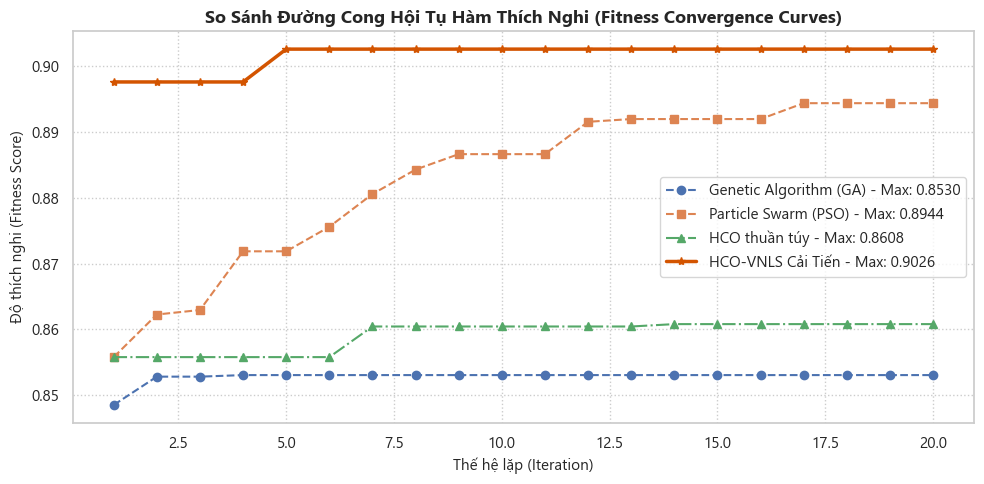

In [4]:
plt.figure(figsize=(10, 5))
iters = range(1, MAX_ITER + 1)
plt.plot(iters, ga_hist, label=f'Genetic Algorithm (GA) - Max: {ga_fit:.4f}', marker='o', linestyle='--')
plt.plot(iters, pso_hist, label=f'Particle Swarm (PSO) - Max: {pso_fit:.4f}', marker='s', linestyle='--')
plt.plot(iters, hco_hist, label=f'HCO thuần túy - Max: {hco_fit:.4f}', marker='^', linestyle='-.')
plt.plot(iters, hco_vnls_hist, label=f'HCO-VNLS Cải Tiến - Max: {hco_vnls_fit:.4f}', marker='*', linewidth=2.5, color='#d35400')

plt.title('So Sánh Đường Cong Hội Tụ Hàm Thích Nghi (Fitness Convergence Curves)', fontsize=13, fontweight='bold')
plt.xlabel('Thế hệ lặp (Iteration)', fontsize=11)
plt.ylabel('Độ thích nghi (Fitness Score)', fontsize=11)
plt.legend(frameon=True)
plt.grid(True, linestyle=':')
plt.tight_layout()
plt.show()

## 4. Đánh Giá Hiệu Năng Phân Loại Trên Tập Kiểm Thử Độc Lập (Test Evaluation)

In [5]:
def evaluate_model_on_test(mask, X_tr, y_tr, X_te, y_te, name):
    if mask is None:
        X_tr_sub, X_te_sub = X_tr, X_te
        n_feats = X_tr.shape[1]
    else:
        indices = np.where(mask == 1)[0]
        X_tr_sub, X_te_sub = X_tr[:, indices], X_te[:, indices]
        n_feats = len(indices)
    
    clf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
    clf.fit(X_tr_sub, y_tr)
    y_pred = clf.predict(X_te_sub)
    y_prob = clf.predict_proba(X_te_sub)[:, 1]
    
    acc = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred, average='weighted')
    rec = recall_score(y_te, y_pred, average='weighted')
    f1 = f1_score(y_te, y_pred, average='weighted')
    auc = roc_auc_score(y_te, y_prob)
    
    return {
        'Phương pháp': name,
        'Số đặc trưng': f'{n_feats}/{X_tr.shape[1]}',
        'Tỷ lệ giảm (%)': f'{(1 - n_feats/X_tr.shape[1])*100:.1f}%',
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc,
        'model': clf,
        'y_prob': y_prob
    }

results = []
results.append(evaluate_model_on_test(None, X_train, y_train, X_test, y_test, 'Baseline (Tất cả đặc trưng)'))
results.append(evaluate_model_on_test(ga_mask, X_train, y_train, X_test, y_test, 'Genetic Algorithm (GA)'))
results.append(evaluate_model_on_test(pso_mask, X_train, y_train, X_test, y_test, 'Particle Swarm (PSO)'))
results.append(evaluate_model_on_test(hco_mask, X_train, y_train, X_test, y_test, 'HCO thuần túy'))
results.append(evaluate_model_on_test(hco_vnls_mask, X_train, y_train, X_test, y_test, 'HCO-VNLS Cải Tiến (Đề xuất)'))

df_res = pd.DataFrame(results).drop(columns=['model', 'y_prob'])
df_res

,Phương pháp,Số đặc trưng,Tỷ lệ giảm (%),Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Baseline (Tất cả đặc trưng),30/30,0.0%,0.930357,0.933104,0.930357,0.930405,0.979852
1,Genetic Algorithm (GA),12/30,60.0%,0.918392,0.921923,0.918392,0.918437,0.972749
2,Particle Swarm (PSO),5/30,83.3%,0.930204,0.932804,0.930204,0.930253,0.978314
3,HCO thuần túy,12/30,60.0%,0.933886,0.936209,0.933886,0.933935,0.980989
4,HCO-VNLS Cải Tiến (Đề xuất),4/30,86.7%,0.930357,0.932937,0.930357,0.930407,0.978464


## 5. Phân Tích Các Đặc Trưng Được Thuật Toán HCO-VNLS Lựa Chọn

Tổng số đặc trưng được chọn: 4 / 30

Danh sách đặc trưng tối ưu:
 01. code_module
 02. total_assessments_taken
 03. weighted_avg_score
 04. clicks_oucontent


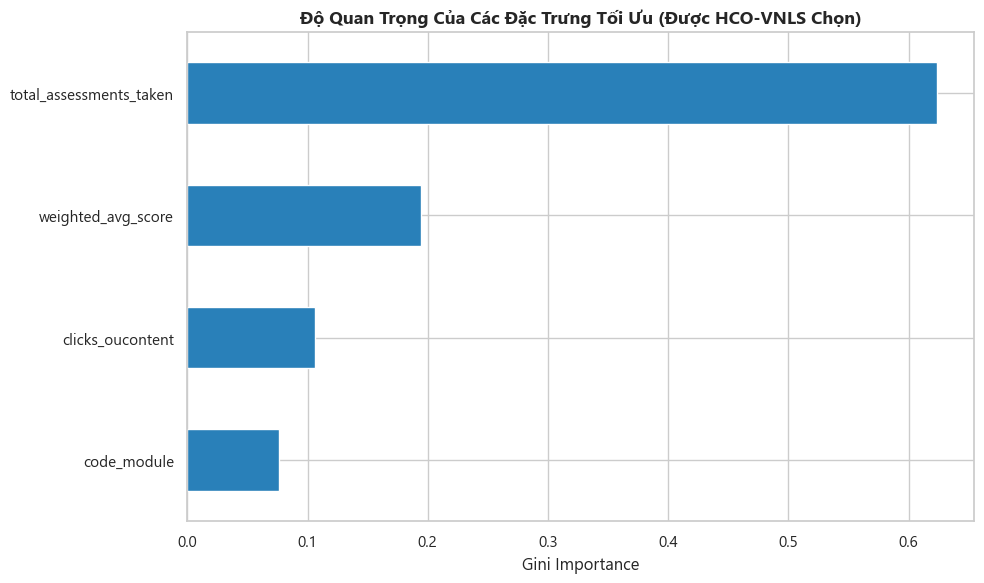

In [6]:
selected_cols = [f for f, m in zip(feature_names, hco_vnls_mask) if m == 1]
print(f'Tổng số đặc trưng được chọn: {len(selected_cols)} / {len(feature_names)}')
print('\nDanh sách đặc trưng tối ưu:')
for idx, col in enumerate(selected_cols, 1):
    print(f' {idx:02d}. {col}')

# Huấn luyện mô hình Random Forest trên tập đặc trưng tối ưu để lấy Feature Importance
hco_vnls_model = results[-1]['model']
importances = hco_vnls_model.feature_importances_
feat_imp = pd.Series(importances, index=selected_cols).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
feat_imp.plot(kind='barh', color='#2980b9')
plt.title('Độ Quan Trọng Của Các Đặc Trưng Tối Ưu (Được HCO-VNLS Chọn)', fontsize=13, fontweight='bold')
plt.xlabel('Gini Importance')
plt.tight_layout()
plt.show()

## 6. Công Cụ Đề Xuất Chiến Lược Học Tập Cá Nhân Hóa (Personalized Learning Recommendation Engine)

In [7]:
# Khởi tạo Recommendation Engine
rec_engine = LearningRecommendationEngine(feature_names=feature_names, feature_mask=hco_vnls_mask)
rec_engine.fit_benchmarks(df_raw, y_all)

print('Giá trị trung vị chuẩn (Benchmark) của nhóm sinh viên khá giỏi:')
for k, v in rec_engine.benchmark_medians.items():
    print(f' - {k}: {v:.2f}')

Giá trị trung vị chuẩn (Benchmark) của nhóm sinh viên khá giỏi:
 - total_assessments_taken: 9.00
 - weighted_avg_score: 74.93
 - clicks_oucontent: 278.00


### 6.1. Thử Nghiệm Gợi Ý Cho Sinh Viên Mẫu Cụ Thể (Case Study)

In [8]:
# Lấy 3 mẫu sinh viên: Sinh viên nguy cơ cao, Sinh viên trung bình, Sinh viên khá giỏi
sample_high_risk = df_raw[(df_raw['final_result'] == 'Fail') & (df_raw['avg_score'] < 40)].iloc[0]
sample_good = df_raw[(df_raw['final_result'] == 'Pass') & (df_raw['avg_score'] > 75)].iloc[0]

# Chẩn đoán sinh viên 1 (Nguy cơ cao)
student_dict_1 = sample_high_risk.to_dict()
risk_prob_1 = 0.82  # Giả lập xác suất dự báo rủi ro từ mô hình
rec_output_1 = rec_engine.generate_student_recommendations(student_dict_1, risk_prob_1)

print('='*70)
print(f'HỒ SƠ TƯ VẤN SINH VIÊN: {student_dict_1["id_student"]} - Khóa học: {student_dict_1["code_module"]}_{student_dict_1["code_presentation"]}')
print(f'Trạng thái cảnh báo: {rec_output_1["status_text"]} (Điểm rủi ro: {rec_output_1["risk_score"]*100:.1f}%)')
print('='*70)
print('\n❌ ĐIỂM YẾU PHÁT HIỆN:')
for w in rec_output_1['weaknesses']:
    print(f'  • {w}')

print('\n📋 CHIẾN LƯỢC HỌC TẬP GỢI Ý CÁ NHÂN HÓA:')
for idx, s in enumerate(rec_output_1['strategies'], 1):
    print(f'  {idx}. [{s["priority"]}] {s["category"]}:')
    print(f'     👉 Hành động: {s["action"]}')
    print(f'     🎯 Mục tiêu: {s["target_metric"]}')
print('='*70)

HỒ SƠ TƯ VẤN SINH VIÊN: 175991 - Khóa học: AAA_2013J
Trạng thái cảnh báo: NGUY CƠ BỎ HỌC / RỚT MÔN CAO (HIGH RISK) (Điểm rủi ro: 82.0%)

❌ ĐIỂM YẾU PHÁT HIỆN:
  • Điểm số bài tập quá thấp (< 50 điểm)
  • Có 2.0 bài nộp trễ hạn
  • Mức độ chuyên cần trên hệ thống thấp (17.0 ngày hoạt động)

📋 CHIẾN LƯỢC HỌC TẬP GỢI Ý CÁ NHÂN HÓA:
  1. [HIGH] Củng cố kiến thức nền tảng:
     👉 Hành động: Xem lại tài nguyên giảng dạy cốt lõi (oucontent) các tuần trước và làm lại các bài tập trắc nghiệm ngắn tự luyện.
     🎯 Mục tiêu: Nâng điểm trung bình từ 37.6 lên trên 70.0 điểm.
  2. [HIGH] Quản lý thời gian & Hạn chót:
     👉 Hành động: Lập lịch biểu cá nhân hóa, đặt mốc hoàn thành trước hạn nộp chính thức 48 giờ để kịp rà soát bài nộp.
     🎯 Mục tiêu: Giảm số lần trễ hạn về 0 bài.
  3. [HIGH] Độ chuyên cần & Tính liên tục:
     👉 Hành động: Tạo thói quen đăng nhập LMS tối thiểu 4 ngày/tuần, mỗi phiên ít nhất 30-45 phút.
     🎯 Mục tiêu: Tăng ngày hoạt động lên tối thiểu 36 ngày.
  4. [MEDIUM] Học tậ

### 6.2. Trực Quan Hóa Radar Chart Chẩn Đoán Sinh Viên

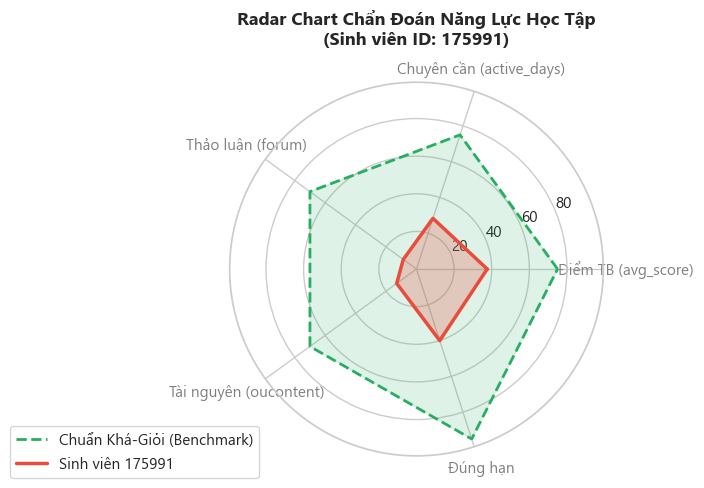

In [9]:
categories = ['Điểm TB (avg_score)', 'Chuyên cần (active_days)', 'Thảo luận (forum)', 'Tài nguyên (oucontent)', 'Đúng hạn']
N = len(categories)

# Chuẩn hóa điểm 0-100 để vẽ biểu đồ Radar
student_vals = [
    min(100, student_dict_1.get('avg_score', 0)),
    min(100, (student_dict_1.get('active_days', 0) / 60) * 100),
    min(100, (student_dict_1.get('clicks_forumng', 0) / 150) * 100),
    min(100, (student_dict_1.get('clicks_oucontent', 0) / 500) * 100),
    max(0, 100 - student_dict_1.get('late_submissions', 0) * 30)
]
student_vals += student_vals[:1]

benchmark_vals = [75, 75, 70, 70, 95]
benchmark_vals += benchmark_vals[:1]

angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

plt.figure(figsize=(7, 7))
ax = plt.subplot(111, polar=True)
plt.xticks(angles[:-1], categories, color='grey', size=11)

# Vẽ đường Benchmark chuẩn
ax.plot(angles, benchmark_vals, linewidth=2, linestyle='dashed', label='Chuẩn Khá-Giỏi (Benchmark)', color='#27ae60')
ax.fill(angles, benchmark_vals, color='#27ae60', alpha=0.15)

# Vẽ đường của sinh viên
ax.plot(angles, student_vals, linewidth=2.5, linestyle='solid', label=f'Sinh viên {student_dict_1["id_student"]}', color='#e74c3c')
ax.fill(angles, student_vals, color='#e74c3c', alpha=0.25)

plt.title(f'Radar Chart Chẩn Đoán Năng Lực Học Tập\n(Sinh viên ID: {student_dict_1["id_student"]})', size=13, fontweight='bold', y=1.08)
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.tight_layout()
plt.show()